# Analysis of Experimental Data

This notebook follows an example trackpy project from start to finish. 


## Scientific IPython Setup

We need Python's plotting library, matplotlib. Your environment might load matplotlib automatically, but for this tutorial I'll load it explicitly using this convention. If you are unfamiliar with matplotlib, do the same as I do here, and everything that follows will work without modification.

In [1]:
from __future__ import division, unicode_literals, print_function  # for compatibility with Python 2 and 3

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit  # Ensure this import is present
from scipy.stats import norm
from ipywidgets import IntText, Text, interact  # Ensure this import is present
from scipy.optimize import curve_fit
from IPython.display import display, clear_output
from sklearn.neighbors import KernelDensity
from matplotlib.colors import Normalize
import ipywidgets as widgets


# change the following to %matplotlib notebook for interactive plotting
%matplotlib inline

# Optionally, tweak styles.
mpl.rc('figure',  figsize=(10, 5))
mpl.rc('image', cmap='gray')

import numpy as np
import pandas as pd
from pandas import DataFrame, Series  # for convenience

import pims
import trackpy as tp


## Step 1: Read the Data

### Opening images or video

Video in the E:

In [2]:
# @pims.pipeline
# def gray(image):
#     # Check if the image has more than two dimensions (e.g., RGB)
#     if image.ndim == 3:
#         return image[:, :, 0]  # Return the first channel (e.g., Red for RGB)
#     else:
#         return image  # Return the 2D grayscale image as is
# # Load frames
# frames = gray(pims.open('30C_AfterActivation/*.jpg'))
# file_path = '30C_AfterActivation_07152025.csv'


######################  Normalization #############################
# #Function to normalize brightness automatically
# def auto_normalize_brightness(frames):
    
#     # Compute mean brightness for each frame
#     mean_brightness = [np.mean(frame) for frame in frames]
    
#     # Find the maximum mean brightness to normalize relative to it
#     max_brightness = max(mean_brightness)
    
#     # Normalize all frames relative to the maximum brightness
#     normalized_frames = []
#     for i, frame in enumerate(frames):
#         if mean_brightness[i] > 0:  # Avoid division by zero
#             normalized_frame = frame / mean_brightness[i] * max_brightness
#         else:
#             normalized_frame = frame  # Leave unchanged if mean brightness is zero
        
#         normalized_frames.append(normalized_frame)
    
#     return normalized_frames

# # Normalize the frames
# frames = auto_normalize_brightness(frames)

We can access any frame like `frames[frame_number]`. The image is represented as a numpy array of intensities. If you're using the [Anaconda distribution](https://www.anaconda.com/distribution/) of Python, these should be in the range [0, 255]. If you have a more custom environment they may be in the range [0, 1], in which case you'll have to experiment with the `minmass` parameters below.

In [86]:
# === Apply the mask to all frames ===

import pims
import pandas as pd
import numpy as np
from PIL import Image, ImageDraw

frames = gray_roi_masked(pims.open('30C_AfterActivation/*.jpg'))

# === Load ROI CSV ===
roi_df = pd.read_csv("30C_ROI_Coordinates.csv")
roi_labels = roi_df['Label'].unique()
print(f"Found ROIs: {roi_labels}")
scale_factor = 1.5  # <<< Change this to control scaling
file_path = '30C_AfterActivation_07152025.csv'

def scale_polygon(coords, scale):
    """Scale a polygon around its centroid"""
    coords = np.array(coords)
    centroid = coords.mean(axis=0)
    scaled_coords = centroid + scale * (coords - centroid)
    return [tuple(pt) for pt in scaled_coords]

def create_scaled_roi_mask(roi_df, roi_labels, image_shape, scale=1.0):
    """Create one combined mask from scaled ROI polygons"""
    mask_img = Image.new('L', image_shape[::-1], 0)  # PIL expects (width, height)
    draw = ImageDraw.Draw(mask_img)

    for label in roi_labels:
        coords = roi_df[roi_df['Label'] == label]
        polygon = [(row['X'], row['Y']) for _, row in coords.iterrows()]
        if len(polygon) < 3:
            continue  # skip degenerate polygons
        scaled_polygon = scale_polygon(polygon, scale)
        draw.polygon(scaled_polygon, fill=255)

    return np.array(mask_img) > 0  # Convert to boolean mask

# === Load first frame to get shape ===
test_frame = pims.open('30C_AfterActivation/*.jpg')[0]
if test_frame.ndim == 3:
    test_frame = test_frame[:, :, 0]
image_shape = test_frame.shape  # (height, width)

# === Build scaled mask once ===
combined_mask = create_scaled_roi_mask(roi_df, roi_labels, image_shape, scale=scale_factor)

@pims.pipeline
def gray_roi_masked(image):
    # Convert to grayscale if needed
    if image.ndim == 3:
        image = image[:, :, 0]

    masked_image = image.copy()
    masked_image[~combined_mask] = 0  # Zero out pixels outside scaled ROI
    return masked_image

# === Apply the mask to all frames ===
frames = gray_roi_masked(pims.open('30C_AfterActivation/*.jpg'))


Found ROIs: ['ROI_0' 'ROI_1' 'ROI_2' 'ROI_3' 'ROI_4' 'ROI_5' 'ROI_6' 'ROI_7' 'ROI_8'
 'ROI_9' 'ROI_10' 'ROI_11' 'ROI_12' 'ROI_13' 'ROI_14' 'ROI_15' 'ROI_16'
 'ROI_17' 'ROI_18' 'ROI_19' 'ROI_20' 'ROI_21' 'ROI_22' 'ROI_23' 'ROI_24'
 'ROI_25' 'ROI_26' 'ROI_27' 'ROI_28' 'ROI_29']


## Step 2: Locate Features

Start with just the first frame. Estimate the size of the features (in pixels). The size must be an odd integer, and it is better to err on the large side, as we'll see below. We estimate 11 pixels.

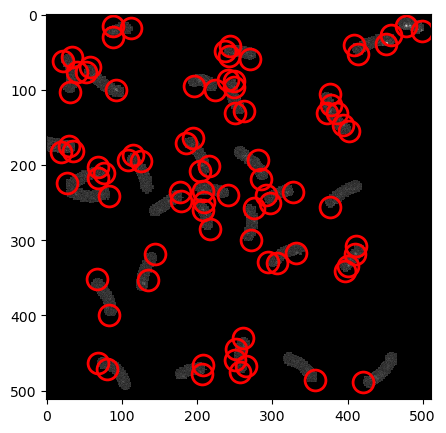

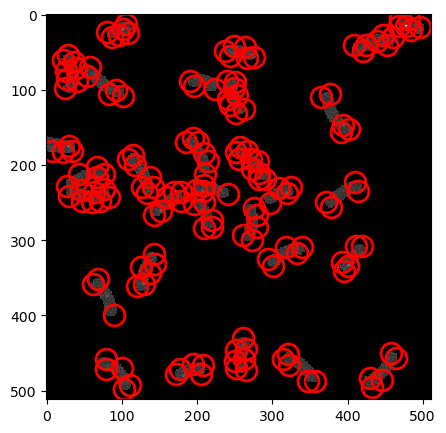

In [87]:
threshold = 13
radius = 7
maxsize = 100
minmass = 40
f = tp.locate(frames[0], radius, invert = False, threshold = threshold, maxsize = maxsize, minmass = minmass)
tp.annotate(f,frames[0]);
f1 = tp.locate(frames[len(frames)-1], radius, invert = False, threshold = threshold, maxsize = maxsize, minmass = minmass)
tp.annotate(f1,frames[len(frames)-1]);

There are more options for controling and optimizing feature-finding. You can review them in the [documentation](https://soft-matter.github.io/trackpy/stable/), where the most comprehensive description is in the API reference. Or, pull them up as you work by typing ``tp.locate?`` into IPython.

### Check for subpixel accuracy
As Eric Weeks points out in his related tutorial, a quick way to check for subpixel accuracy is to check that the decimal part of the x and/or y positions are evenly distributed. Trackpy provides a convenience plotting function for this called `subpx_bias`:

array([[<AxesSubplot:title={'center':'x'}>,
        <AxesSubplot:title={'center':'y'}>]], dtype=object)

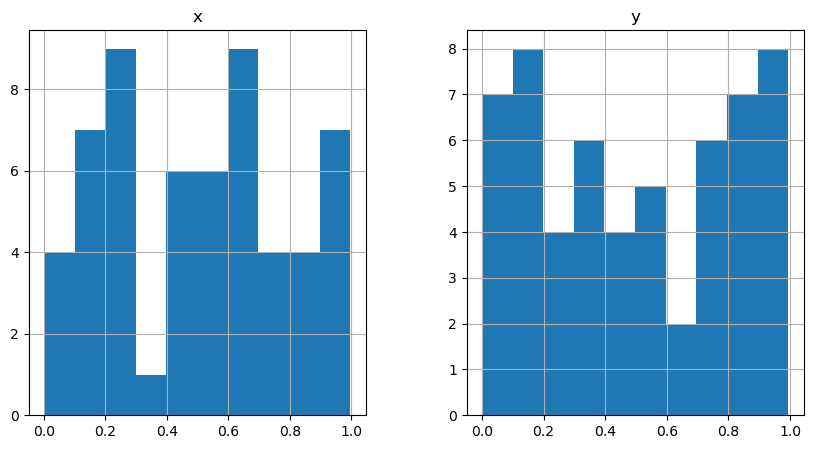

In [48]:
tp.subpx_bias(f)

If we use a mask size that is too small, the histogram often shows a dip in the middle.

In [49]:
f = tp.batch(frames[:], radius, threshold = threshold,invert=False, maxsize = maxsize, minmass = minmass);

As each frame is analyzed, `tp.batch` reports the frame number and how many features were found. If this number runs unexpectedly low or high, you may wish to interrupt it and try different parameters. 

If your images are small, you may find that printing this number actually slows down `batch` significantly! In that case you can run `tp.quiet()` to turn it off.

## Step 3: Link features into particle trajectories
We have the locations of the particles in each frame. Next we'll track particles from frame to frame, giving each one a number for identification.

First, we must must specify a maximum displacement, the farthest a particle can travel between frames. We should choose the smallest reasonable value because a large value slows computation time considerably. In this case, 5 pixels is reasonable.

Second, we allow for the possibility that a particle might be missed for a few frames and then seen again. (Perhaps its "mass" slipped below our cutoff due to noise in the video.) Memory keeps track of disappeared particles and maintains their ID for up to some number of frames after their last appearance. Here we use 3 frames.

In [50]:
tp.quiet()  # Turn off progress reports for best performance
t = tp.link(f, 5, memory=2)

The result is the features DataFrame `f` with an additional column, `particle`, identifying each feature with a label. We denote this new DataFrame `t`.

### Filter spurious trajectories

We have more filtering to do. Ephemeral trajectories — seen only for a few frames — are usually spurious and never useful. The convenience function `filter_stubs` keeps only trajectories that last for a given number of frames.

In [51]:
t.head()
t1 = tp.filter_stubs(t, 5) #seen for 4 frames
t1.head()
# Compare the number of particles in the unfiltered and filtered data.
print('Before:', t['particle'].nunique())
print('After:', t1['particle'].nunique())

Before: 2115
After: 484


We can also filter trajectories by their particles' appearance. At this stage, with trajectories linked, we can look at a feature's "average appearance" throughout its trajectory, giving a more accurate picture.

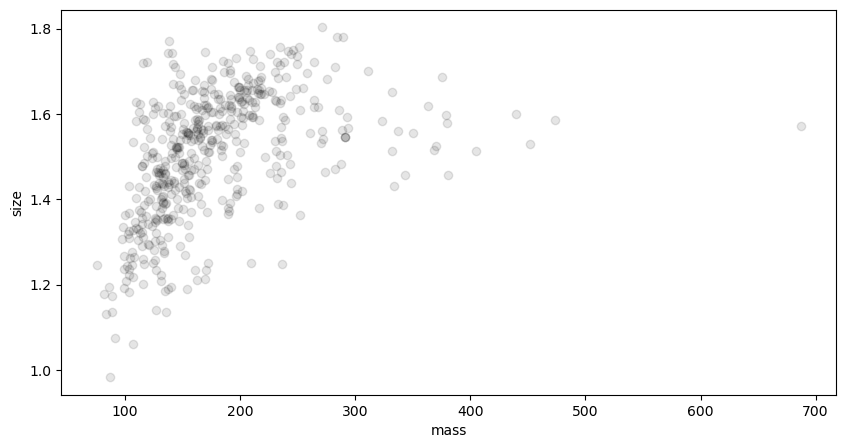

In [52]:
plt.figure()
tp.mass_size(t1.groupby('particle').mean()); # convenience function -- just plots size vs. mass

The particles with especially low mass, or that are especially large or non-circular (eccentric), are probably out of focus or aggregated, respectively. It is best to experiment by trial and error, filtering out regions of mass-size space and looking at the results using `tp.annotate`. In the end, we need to separate the good particles from the spurious ones, and it doesn't matter how we get it done.

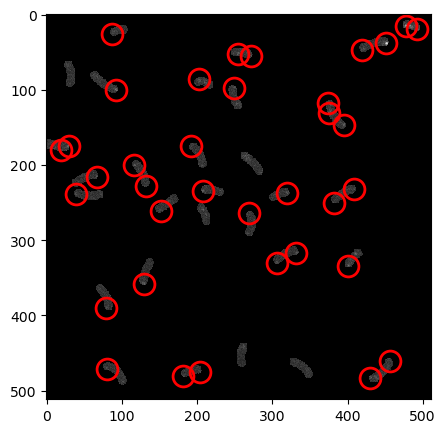

In [53]:
t2 = t1 #primary filter
plt.figure()
tp.annotate(t2[t2['frame'] == 0], frames[0]);
t2.to_csv(file_path, encoding='utf-8', index=False)

# import matplotlib.animation as animation
# from PIL import Image

# # Check the actual number of frames available
# total_frames = len(frames)
# print(f"Total available frames: {total_frames}")

# # Define safe frame range
# start_frame = 0
# end_frame = 499

# # Create figure and axis
# fig, ax = plt.subplots()

# # Update function for each animation frame
# def update(frame_number):
#     ax.clear()
#     image = frames[frame_number]
#     ax.imshow(image, cmap='gray')
#     tp.annotate(t2[t2['frame'] == frame_number], image, ax=ax)
#     ax.set_title(f'Frame {frame_number}')
#     ax.axis('off')
#     return []

# # Create animation only if there's something to animate
# if start_frame <= end_frame:
#     ani = animation.FuncAnimation(
#         fig,
#         update,
#         frames=range(start_frame, end_frame + 1),
#         blit=False,
#         repeat=False
#     )

#     # Save as GIF
#     ani.save(file_path + '.gif', writer='pillow', fps=10)
#     print(f"Animation saved to: {file_path + '.gif'}")
# else:
#     print(f"Invalid frame range: {start_frame} to {end_frame}")


Trace the trajectories using `plot_traj()`:

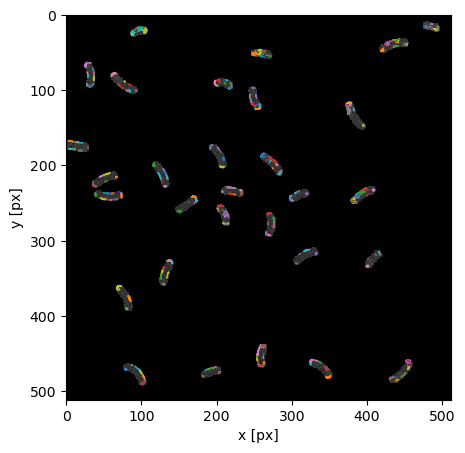

In [54]:
plt.figure()
tp.plot_traj(t2,superimpose=frames[0]);

### Remove overall drift

Compute the overall drifting motion, which we will subtract away, adopting the reference frame of the particles' average position.

In [55]:
t2.to_csv(file_path, encoding='utf-8', index=False) #save out the file to .csv format

In [56]:
# Adding Column of Trajectory Length in CSV file
df = pd.read_csv(file_path)

# Count the number of frames each particle appears in
trajectory_lengths = df.groupby('particle')['frame'].nunique()

# Add the trajectory length as a new column in the original DataFrame
df['trajectory_length'] = df['particle'].map(trajectory_lengths)

# Save the updated DataFrame to a new CSV file
output_file = file_path
df.to_csv(output_file, index=False)

# Return the path to the updated CSV file
output_file

'30C_AfterActivation_07152025.csv'

In [57]:
# Ensure trajectory_length column exists
if 'trajectory_length' not in df.columns:
    trajectory_lengths = df.groupby('particle')['frame'].nunique()
    df['trajectory_length'] = df['particle'].map(trajectory_lengths)

# Global variables to store filtered data
t3 = pd.DataFrame()

# Function to filter, save, and plot the data
def filter_and_plot(min_traj, max_traj, min_mass, max_mass, start_frame, end_frame, particle_ids, min_x, max_x, min_y, max_y):
    global t3  # Declare as global variables
    
    try:
        # Convert inputs to numeric
        min_traj = int(min_traj)
        max_traj = int(max_traj)
        min_mass = float(min_mass)
        max_mass = float(max_mass)
        start_frame = int(start_frame)
        end_frame = int(end_frame)
        min_x = float(min_x)
        max_x = float(max_x)
        min_y = float(min_y)
        max_y = float(max_y)

        # Parse particle IDs input
        if particle_ids.strip():  # If user inputs particle IDs
            selected_particles = [int(pid) for pid in particle_ids.split(',')]
        else:
            selected_particles = None  # Include all particles by default

        # Filter based on trajectory length, mass, frame range, and x/y ranges
        traj_filtered_df = df[
            (df['trajectory_length'] >= min_traj) &
            (df['trajectory_length'] <= max_traj) &
            (df['frame'] >= start_frame) &
            (df['frame'] <= end_frame) &
            (df['x'] >= min_x) & (df['x'] <= max_x) &
            (df['y'] >= min_y) & (df['y'] <= max_y)
        ]
        
        # Further filter by mass range
        valid_particles = traj_filtered_df.groupby('particle').filter(
            lambda x: (x['mass'].min() >= min_mass) and (x['mass'].max() <= max_mass)
        )['particle'].unique()

        # Filter the dataframe to include only valid particles
        t3 = traj_filtered_df[traj_filtered_df['particle'].isin(valid_particles)]

        # Apply Particle ID filter
        if selected_particles:
            t3 = t3[t3['particle'].isin(selected_particles)]

        # Save the filtered data to a new CSV file
        output_file = "Manually_Selected_Single_Molecule_Sample_" + file_path
        t3.to_csv(output_file, index=False)
        print(f"Filtered data saved to {output_file}")
        
        # Plotting
        plt.figure(figsize=(10, 6))
        grouped = t3.groupby('particle')
        
        for particle_id, group in grouped:
            plt.plot(group['frame'], group['mass'], label=f'Particle {particle_id}')
        
        # Add labels and legends
        plt.xlabel('Frame Number')
        plt.ylabel('Mass')
        plt.title('Particle Mass vs Frame Number (Filtered by Range)')
        plt.tight_layout()
        #plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')####################################################
        plt.grid()
        plt.show()
        
    except ValueError as e:
        print("Error:", e)
        print("Please enter valid numerical inputs for trajectory length, mass ranges, frame ranges, and x/y ranges.")

# Create manual input fields for user inputs
traj_manual_min = Text(value="5", description="Min Traj Length:")
traj_manual_max = Text(value=str(df['trajectory_length'].max()), description="Max Traj Length:")
mass_manual_min = Text(value=str(df['mass'].min()), description="Min Mass:")
mass_manual_max = Text(value=str(df['mass'].max()), description="Max Mass:")
frame_start = IntText(value=0, description="Start Frame:")
frame_end = IntText(value=len(df['frame'].unique()), description="End Frame:")
particle_ids_input = Text(value="", description="Particle IDs (comma-separated):")
x_min_input = Text(value=str(df['x'].min()), description="Min X:")
x_max_input = Text(value=str(df['x'].max()), description="Max X:")
y_min_input = Text(value=str(df['y'].min()), description="Min Y:")
y_max_input = Text(value=str(df['y'].max()), description="Max Y:")

# Interactive widget to trigger the function
interact(filter_and_plot, 
         min_traj=traj_manual_min, 
         max_traj=traj_manual_max, 
         min_mass=mass_manual_min, 
         max_mass=mass_manual_max,
         start_frame=frame_start,
         end_frame=frame_end,
         particle_ids=particle_ids_input,
         min_x=x_min_input,
         max_x=x_max_input,
         min_y=y_min_input,
         max_y=y_max_input);


interactive(children=(Text(value='5', description='Min Traj Length:'), Text(value='200', description='Max Traj…

In [63]:
#Frequency vs Avg Mass
if 'particle' not in df.columns or 'frame' not in df.columns or 'mass' not in df.columns:
    raise ValueError("The CSV file must include 'particle', 'frame', and 'mass' columns.")

# Function to analyze and plot frequency of mass for a single particle
def plot_particle_mass_histogram(particle_id):
    # Filter the data for the selected particle
    particle_data = df[df['particle'] == particle_id]
    
    if particle_data.empty:
        print(f"No data found for particle ID: {particle_id}")
        return
    
    # Calculate the standard deviation of the mass
    mass_std = particle_data['mass'].std()

    # Plot the histogram of mass frequency
    plt.figure(figsize=(10, 6))
    plt.hist(particle_data['mass'], bins=20, color='skyblue', edgecolor='black')
    plt.xlabel('Mass')
    plt.ylabel('Frequency')
    plt.title(f'Frequency of Mass for Particle ID: {particle_id}\n(Standard Deviation: {mass_std:.4f})')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # Display summary
    print(f"Particle ID: {particle_id}")
    print(f"Number of Frames: {particle_data['frame'].nunique()}")
    print(f"Mass Range: {particle_data['mass'].min()} to {particle_data['mass'].max()}")
    print(f"Standard Deviation of Mass: {mass_std:.4f}")

# Create an interactive widget for inputting particle ID
particle_id_input = IntText(value=0, description="Particle ID:")

# Create interactive output
interact(plot_particle_mass_histogram, particle_id=particle_id_input);


interactive(children=(IntText(value=0, description='Particle ID:'), Output()), _dom_classes=('widget-interact'…

/var/folders/0k/3k6whtl53gzbzkn6wq663f5c0000gn/T/ipykernel_82471/4280322503.py:19: RuntimeWarning: divide by zero encountered in divide
  gaussian2 = amp2 * np.exp(-0.5 * ((x - mean2) / sigma2) ** 2)
/var/folders/0k/3k6whtl53gzbzkn6wq663f5c0000gn/T/ipykernel_82471/4280322503.py:18: RuntimeWarning: divide by zero encountered in divide
  gaussian1 = amp1 * np.exp(-0.5 * ((x - mean1) / sigma1) ** 2)


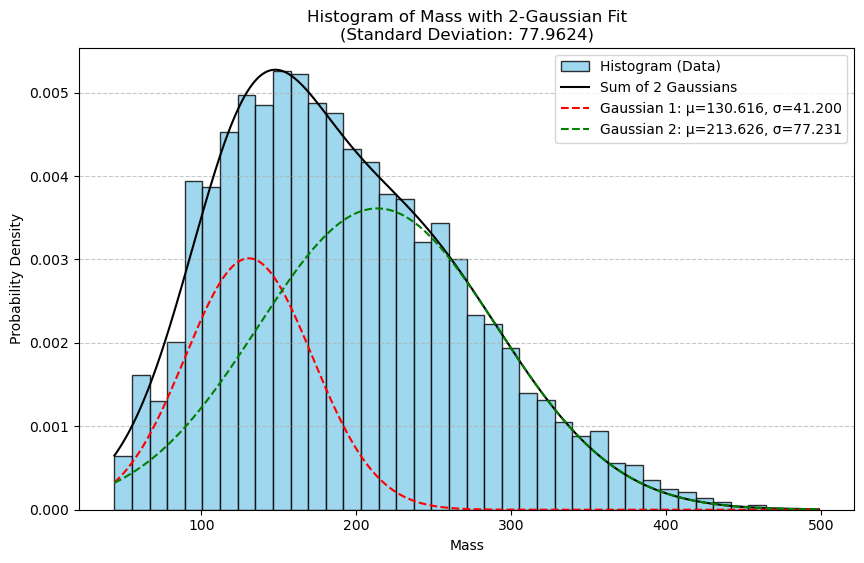

Fitted Parameters:
  Gaussian 1: Amplitude=0.003, Mean (μ)=130.616, σ=41.200
  Gaussian 2: Amplitude=0.004, Mean (μ)=213.626, σ=77.231

Stored Gaussian 1 Parameters:
  Mean (μ): 130.616
  Standard Deviation (σ): 41.200

Global Gaussian 1 Mean: 130.616
Global Gaussian 1 Standard Deviation: 41.200


In [64]:
import seaborn as sns

# Global variables to store Gaussian 1 parameters
gaussian1_mean = None
gaussian1_sigma = None

# Load the CSV file
filtered_file_path = "Manually_Selected_Single_Molecule_Sample_" + file_path
df = pd.read_csv(filtered_file_path)

# Ensure necessary columns exist
required_columns = {'particle', 'frame', 'mass'}
if not required_columns.issubset(df.columns):
    raise ValueError(f"The CSV file must include the following columns: {', '.join(required_columns)}")

# Define the sum of two Gaussian functions
def double_gaussian(x, amp1, mean1, sigma1, amp2, mean2, sigma2):
    gaussian1 = amp1 * np.exp(-0.5 * ((x - mean1) / sigma1) ** 2)
    gaussian2 = amp2 * np.exp(-0.5 * ((x - mean2) / sigma2) ** 2)
    return gaussian1 + gaussian2

# Function to plot the histogram and fit it to 2 Gaussians
def plot_and_fit_histogram():
    global gaussian1_mean, gaussian1_sigma  # Declare global variables

    # Drop NaNs and prepare data
    data = df['mass'].dropna()
    if data.empty:
        print("No mass data available to fit.")
        return

    # Compute histogram
    hist, bins = np.histogram(data, bins=30, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2

    # Estimate mean and std
    mean_mass = data.mean()
    std_mass = data.std()

    # Initial guesses for the two Gaussians
    p0 = [
        max(hist), mean_mass * 0.9, std_mass * 0.5,     # Gaussian 1
        max(hist) * 0.6, mean_mass * 1.1, std_mass      # Gaussian 2
    ]

    # Attempt fitting with error handling
    try:
        popt, _ = curve_fit(double_gaussian, bin_centers, hist, p0=p0, maxfev=10000)
    except RuntimeError as e:
        print("Curve fitting failed:", e)
        return

    # Extract fitted parameters
    gaussian1_params = popt[:3]
    gaussian2_params = popt[3:]

    # Store Gaussian 1 parameters globally
    gaussian1_mean = gaussian1_params[1]
    gaussian1_sigma = gaussian1_params[2]

    # Plot histogram and fit
    plt.figure(figsize=(10, 6))
    plt.hist(data, bins=40, density=True, color='skyblue', edgecolor='black', alpha=0.8, label="Histogram (Data)")
    x_fit = np.linspace(min(data), max(data), 1000)
    total_fit = double_gaussian(x_fit, *popt)

    plt.plot(x_fit, total_fit, 'k-', label="Sum of 2 Gaussians")
    plt.plot(x_fit, double_gaussian(x_fit, *gaussian1_params, 0, 0, 0), 'r--',
             label=f"Gaussian 1: μ={gaussian1_mean:.3f}, σ={gaussian1_sigma:.3f}")
    plt.plot(x_fit, double_gaussian(x_fit, 0, 0, 0, *gaussian2_params), 'g--',
             label=f"Gaussian 2: μ={gaussian2_params[1]:.3f}, σ={gaussian2_params[2]:.3f}")

    plt.xlabel('Mass')
    plt.ylabel('Probability Density')
    plt.title(f'Histogram of Mass with 2-Gaussian Fit\n(Standard Deviation: {std_mass:.4f})')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # Print fitted parameters
    print("Fitted Parameters:")
    print(f"  Gaussian 1: Amplitude={gaussian1_params[0]:.3f}, Mean (μ)={gaussian1_mean:.3f}, σ={gaussian1_sigma:.3f}")
    print(f"  Gaussian 2: Amplitude={gaussian2_params[0]:.3f}, Mean (μ)={gaussian2_params[1]:.3f}, σ={gaussian2_params[2]:.3f}")

    print("\nStored Gaussian 1 Parameters:")
    print(f"  Mean (μ): {gaussian1_mean:.3f}")
    print(f"  Standard Deviation (σ): {gaussian1_sigma:.3f}")

# Run the fitting and plot
plot_and_fit_histogram()

# Output the stored Gaussian 1 parameters for external use
if gaussian1_mean is not None and gaussian1_sigma is not None:
    print(f"\nGlobal Gaussian 1 Mean: {gaussian1_mean:.3f}")
    print(f"Global Gaussian 1 Standard Deviation: {gaussian1_sigma:.3f}")


'sigma_mass_across_frame' has been written to Manually_Selected_Single_Molecule_Sample_30C_AfterActivation_07152025.csv.


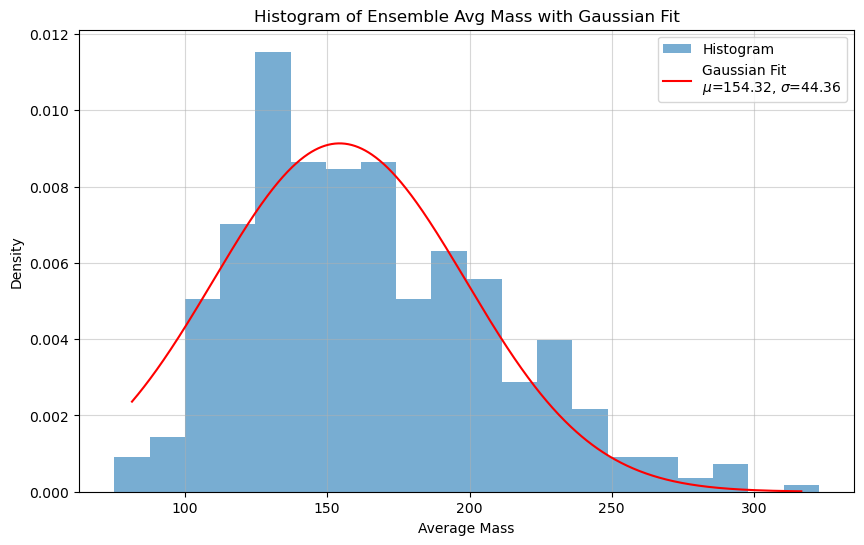

Standard Deviation of the Gaussian Fit for Avg Mass: 44.36


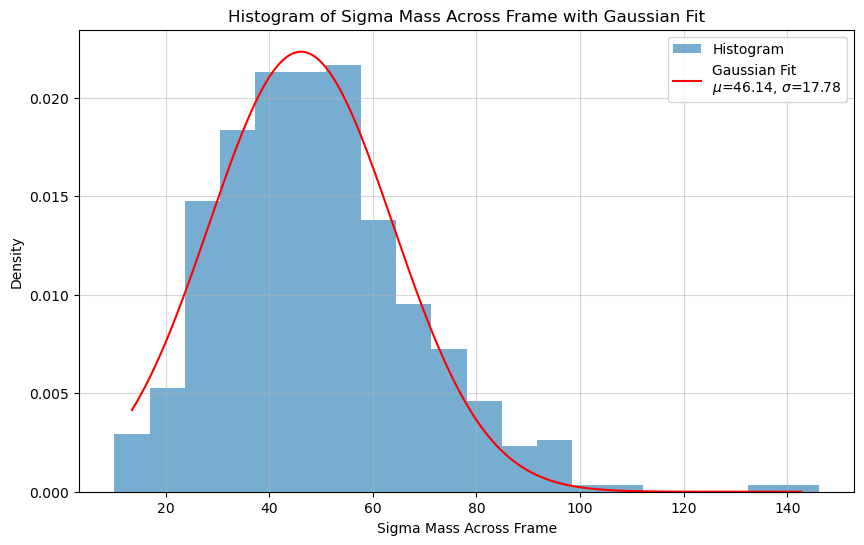

Standard Deviation of the Gaussian Fit for Sigma Mass Across Frame: 17.78


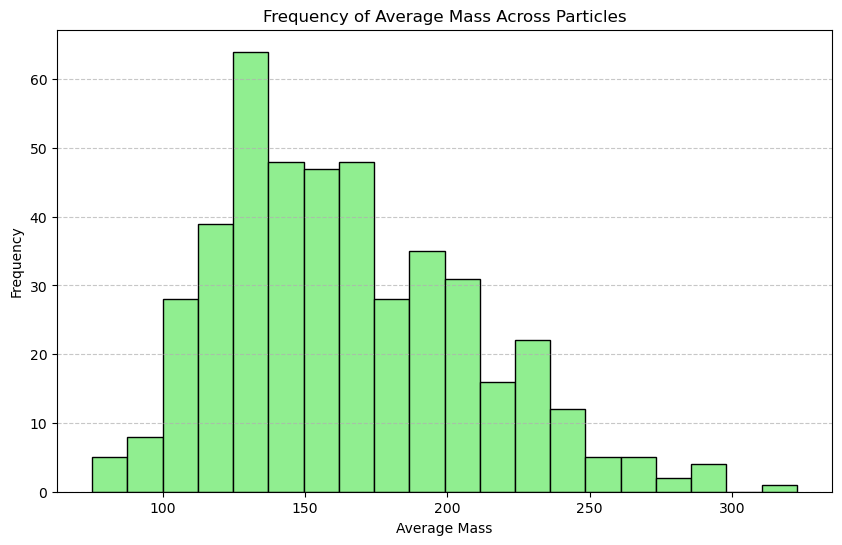

Total Particles Analyzed: 448
Average Mass Range: 75.18474460959972 to 322.81187503462473
Updated file with classification and average_mass saved to 30C_AfterActivation_07152025.csv
Classification Summary:
single molecule    383
cluster            101
Name: classification, dtype: int64


In [65]:
# Global variables to store the standard deviations
std_fit_avg_mass = None
std_fit_sigma_mass = None

# Reload the manually selected sample CSV file
file_name = "Manually_Selected_Single_Molecule_Sample_" + file_path
selected_df = pd.read_csv(file_name)

# Compute sigma_mass_across_frame for each particle and write back to the original CSV
selected_df['sigma_mass_across_frame'] = selected_df.groupby('particle')['mass'].transform('std')
selected_df.to_csv(file_name, index=False)  # Save the updated data to the original CSV
print(f"'sigma_mass_across_frame' has been written to {file_name}.")

# Function to perform Gaussian fit and plot histogram
def plot_histogram_with_gaussian(data, xlabel, title):
    # Compute standard deviation of the data
    std_data = data.std()

    # Define the Gaussian function
    def gaussian(x, amp, mu, sigma):
        return amp * np.exp(-(x - mu)**2 / (2 * sigma**2))

    # Create the histogram
    hist, bins = np.histogram(data, bins=20, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2

    try:
        # Fit the Gaussian to the histogram
        popt, _ = curve_fit(
            gaussian,
            bin_centers,
            hist,
            p0=[hist.max(), data.mean(), std_data],
            maxfev=5000  # Increase maximum evaluations
        )

        # Extract fitted parameters
        amp_fit, mu_fit, sigma_fit = popt

        # Plot the histogram and Gaussian fit
        plt.figure(figsize=(10, 6))
        plt.hist(data, bins=20, density=True, alpha=0.6, label='Histogram')
        x_vals = np.linspace(bin_centers.min(), bin_centers.max(), 1000)
        plt.plot(
            x_vals, gaussian(x_vals, *popt), color='red', 
            label=f'Gaussian Fit\n$\mu$={mu_fit:.2f}, $\sigma$={sigma_fit:.2f}'
        )
        plt.xlabel(xlabel)
        plt.ylabel('Density')
        plt.title(title)
        plt.legend()
        plt.grid(alpha=0.5)

        # Show plot
        plt.show()

        # Return the standard deviation of the fit
        return sigma_fit

    except RuntimeError as e:
        print(f"Gaussian fit failed: {e}")
        return None

# Plot and fit for average mass
avg_mass_per_particle = selected_df.groupby('particle')['mass'].mean()
std_fit_avg_mass = plot_histogram_with_gaussian(
    avg_mass_per_particle, 'Average Mass', 'Histogram of Ensemble Avg Mass with Gaussian Fit'
)
if std_fit_avg_mass is not None:
    print(f"Standard Deviation of the Gaussian Fit for Avg Mass: {std_fit_avg_mass:.2f}")
else:
    print("Gaussian fit for Avg Mass failed.")

# Plot and fit for sigma_mass_across_frame
sigma_mass_across_frame_per_particle = selected_df.groupby('particle')['sigma_mass_across_frame'].first().dropna()
std_fit_sigma_mass = plot_histogram_with_gaussian(
    sigma_mass_across_frame_per_particle, 'Sigma Mass Across Frame', 'Histogram of Sigma Mass Across Frame with Gaussian Fit'
)
if std_fit_sigma_mass is not None:
    print(f"Standard Deviation of the Gaussian Fit for Sigma Mass Across Frame: {std_fit_sigma_mass:.2f}")
else:
    print("Gaussian fit for Sigma Mass Across Frame failed.")

#Ensemble of Avg Mass
# Ensure necessary columns exist
if 'particle' not in df.columns or 'frame' not in df.columns or 'mass' not in df.columns:
    raise ValueError("The CSV file must include 'particle', 'frame', and 'mass' columns.")

# Function to compute the average mass for each particle and plot a histogram
def plot_average_mass_distribution():
    # Compute the average mass for each particle
    avg_mass = df.groupby('particle')['mass'].mean().reset_index()
    avg_mass.columns = ['particle', 'average_mass']
    
    # Plot the histogram of average mass
    plt.figure(figsize=(10, 6))
    plt.hist(avg_mass['average_mass'], bins=20, color='lightgreen', edgecolor='black')
    plt.xlabel('Average Mass')
    plt.ylabel('Frequency')
    plt.title('Frequency of Average Mass Across Particles')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # Print summary
    print(f"Total Particles Analyzed: {len(avg_mass)}")
    print(f"Average Mass Range: {avg_mass['average_mass'].min()} to {avg_mass['average_mass'].max()}")

# Run the function
plot_average_mass_distribution()


# Reload the file_path CSV
df = pd.read_csv(file_path)

# Ensure the classification column is dropped if it already exists
if 'classification' in df.columns:
    df.drop(columns=['classification'], inplace=True)

# Compute sigma_mass_across_frame for each particle
df['sigma_mass_across_frame'] = df.groupby('particle')['mass'].transform('std')

# Compute average_mass for each particle and assign it as a new column
df['average_mass'] = df.groupby('particle')['mass'].transform('mean')

# Load manually selected single molecule CSV
manual_file_name = "Manually_Selected_Single_Molecule_Sample_" + file_path
manual_df = pd.read_csv(manual_file_name)

# Compute avg mass and sigma_mass_across_frame statistics for manually selected particles
avg_mass_manual = manual_df.groupby('particle')['mass'].mean()
sigma_mass_across_frame_manual = manual_df.groupby('particle')['sigma_mass_across_frame'].first().dropna()

# Compute global statistics from manually selected particles
mean_avg_mass_manual = avg_mass_manual.mean()
std_fit_avg_mass = avg_mass_manual.std()

mean_sigma_mass_manual = sigma_mass_across_frame_manual.mean()
std_fit_sigma_mass = sigma_mass_across_frame_manual.std()

# Define classification conditions
# avg_mass_lower_bound = mean_avg_mass_manual - 1.5 * std_fit_avg_mass
# avg_mass_upper_bound = mean_avg_mass_manual + 1.5 * std_fit_avg_mass
avg_mass_lower_bound = 0
avg_mass_upper_bound = gaussian1_mean + 2 * gaussian1_sigma #################################################################################

#sigma_mass_lower_bound = mean_sigma_mass_manual - 2 * std_fit_sigma_mass
#sigma_mass_upper_bound = mean_sigma_mass_manual + 2 * std_fit_sigma_mass

# Compute average mass for each particle in the original file
particle_avg_mass = df.groupby('particle')['mass'].mean().reset_index()
particle_avg_mass.columns = ['particle', 'average_mass']

# Merge average mass and sigma_mass_across_frame into a single DataFrame
particle_stats = df[['particle', 'sigma_mass_across_frame']].drop_duplicates().merge(
    particle_avg_mass, on='particle'
)


def classify_particle(row):
    if (
        avg_mass_lower_bound <= row['average_mass'] <= avg_mass_upper_bound
    ):
        return 'single molecule'
    elif (
        row['average_mass'] > avg_mass_upper_bound
    ):
        return 'cluster'


# Create or overwrite the 'classification' column
particle_stats['classification'] = particle_stats.apply(classify_particle, axis=1)

# Merge the updated classification into the main DataFrame
df = df.merge(particle_stats[['particle', 'classification']], on='particle', how='left')

# Save the updated DataFrame back to the same CSV file
df.to_csv(file_path, index=False)
print(f"Updated file with classification and average_mass saved to {file_path}")

# Print classification summary
classification_summary = particle_stats['classification'].value_counts()
print("Classification Summary:")
print(classification_summary)


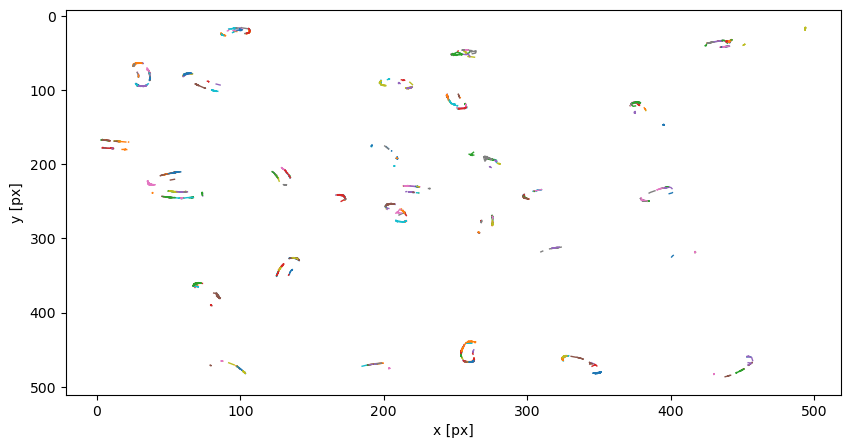

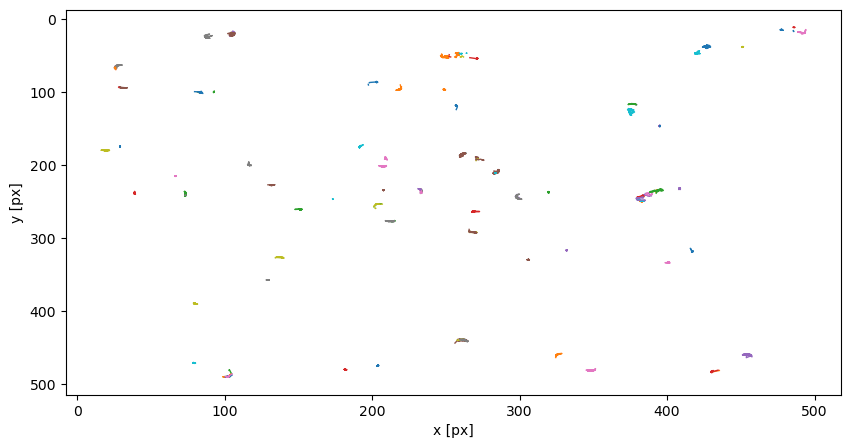

Drift for single_molecule computed successfully.
Drift for cluster computed successfully.


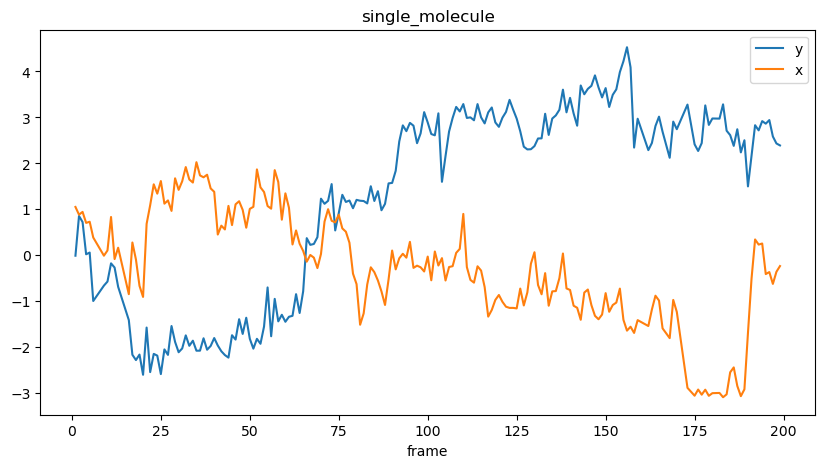

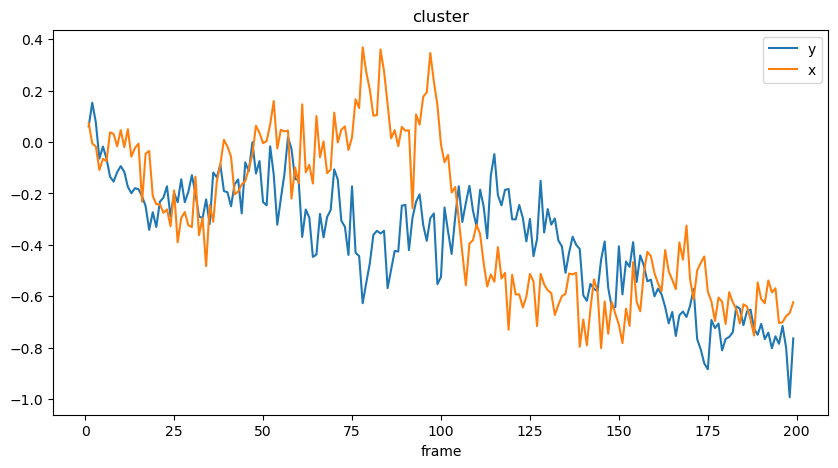

0.06474820143884892


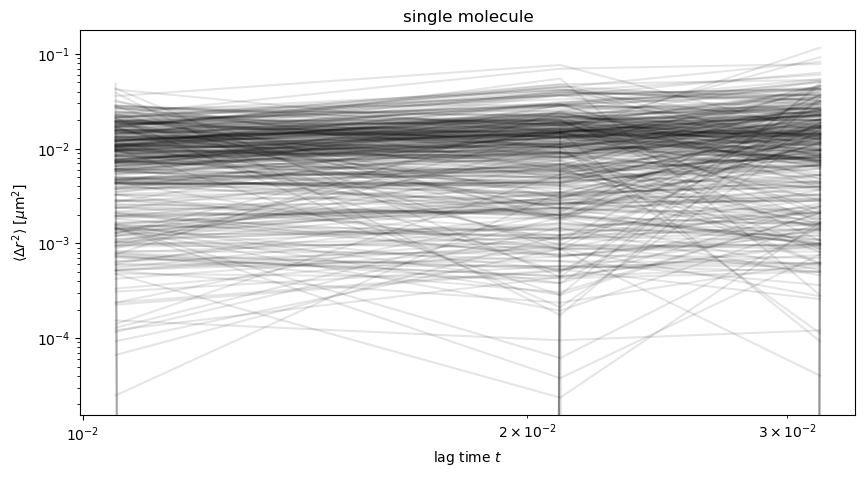

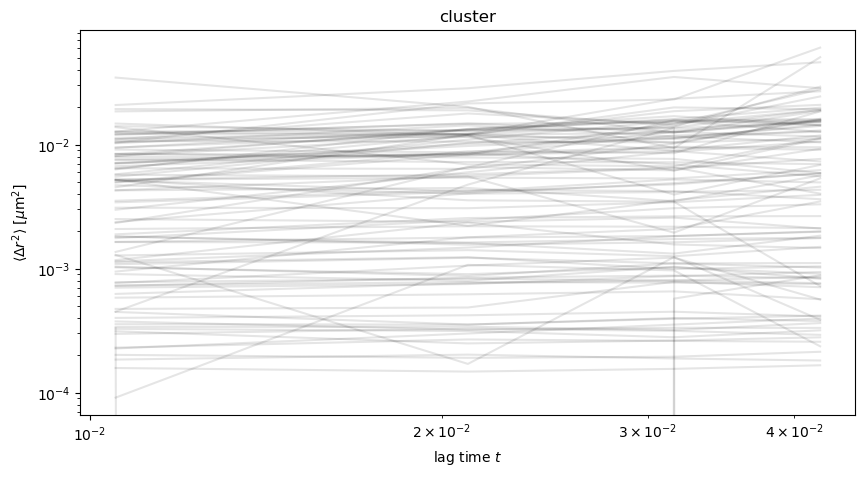

In [77]:
# Compute for Single Molecule & Cluster
##
###
##
#
t2 = df.copy()
single_molecule = t2[(t2['classification'] == 'single molecule')]
cluster = t2[(t2['classification'] == 'cluster')]

##############################Plot Trajectory without Drift Substraction############################
try:
    ax_sigle_molecule = tp.plot_traj(single_molecule,label = False)
except TypeError:
    pass

try:
    ax_cluster = tp.plot_traj(cluster,label = False)
except TypeError:
    pass
plt.show()

#compute drift
if single_molecule is not None:
    try:
        d_single_molecule = tp.compute_drift(single_molecule)
        print("Drift for single_molecule computed successfully.")
    except Exception as e:
        print(f"Error computing drift for single_molecule: {e}")
else:
    d_single_molecule = None
    print("Skipping drift computation for single_molecule.")

if cluster is not None:
    try:
        d_cluster = tp.compute_drift(cluster)
        print("Drift for cluster computed successfully.")
    except Exception as e:
        print(f"Error computing drift for cluster: {e}")
else:
    d_cluster = None
    print("Skipping drift computation for cluster.")

#Plot
d_single_molecule.plot()
plt.title('single_molecule')
d_cluster.plot()
plt.title('cluster')
plt.show()

# ############################## Drift Substraction & Plot Trajectory   ################################
# if single_molecule is not None and d_single_molecule is not None:
#     try:
#         tm_single_molecule = tp.subtract_drift(single_molecule.copy(), d_single_molecule)
#         print("Drift subtracted for single_molecule, stored in tm_single_molecule.")
#     except Exception as e:
#         tm_single_molecule = None
#         print(f"Error subtracting drift for single_molecule: {e}")
# else:
#     tm_single_molecule = None
#     print("Skipping drift subtraction for single_molecule.")

# if cluster is not None and d_cluster is not None:
#     try:
#         tm_cluster = tp.subtract_drift(cluster.copy(), d_cluster)
#         print("Drift subtracted for t2, stored in tm.")
#     except Exception as e:
#         tm_cluster = None
#         print(f"Error subtracting drift for cluster: {e}")
# else:
#     tm_cluster = None
#     print("Skipping drift subtraction for cluster.")
 
# try:
#     ax_sigle_molecule = tp.plot_traj(tm_single_molecule,label = False)
# except TypeError:
#     pass

# try:
#     ax_cluster = tp.plot_traj(tm_cluster,label = False)
# except TypeError:
#     pass
# plt.show()


#IMSD
print(90/1390) #measured mpp
try:
    im_single_molecule = tp.imsd(single_molecule, 0.04545, 95, max_lagtime=3)  # microns per pixel = 0.11, frames per second = 50
except KeyError:
    print("Error processing single_molecule Skipping...")
    im_single_molecule = None

try:
    im_cluster = tp.imsd(cluster, 0.04545, 95, max_lagtime=4)
except KeyError:
    print("Error processing cluster Skipping...")
    im_cluster = None
plt.show()

if im_single_molecule is not None:
    fig, ax_single_molecule = plt.subplots()
    ax_single_molecule.plot(im_single_molecule.index, im_single_molecule, 'k-', alpha=0.1)  # black lines, semitransparent
    ax_single_molecule.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
           xlabel='lag time $t$',
           title='single molecule')
    ax_single_molecule.set_xscale('log')
    ax_single_molecule.set_yscale('log')

if im_cluster is not None:
    fig, ax_cluster = plt.subplots()
    ax_cluster.plot(im_cluster.index, im_cluster, 'k-', alpha=0.1)  # black lines, semitransparent
    ax_cluster.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
           xlabel='lag time $t$',
           title='cluster')
    ax_cluster.set_xscale('log')
    ax_cluster.set_yscale('log')
    

Skipping particle 108: fewer than 3 valid MSD points.
Skipping particle 129: fewer than 3 valid MSD points.
Skipping particle 887: fewer than 3 valid MSD points.
Skipping particle 902: fewer than 3 valid MSD points.
Skipping particle 962: fewer than 3 valid MSD points.
Skipping particle 1145: fewer than 3 valid MSD points.
Skipping particle 1268: fewer than 3 valid MSD points.
Skipping particle 1477: fewer than 3 valid MSD points.
Skipping particle 1685: fewer than 3 valid MSD points.
Skipping particle 1793: fewer than 3 valid MSD points.
Skipping particle 1879: fewer than 3 valid MSD points.
✅ Updated CSV saved to: 30C_AfterActivation_07152025.csv
✅ Updated CSV saved to: 30C_AfterActivation_07152025.csv


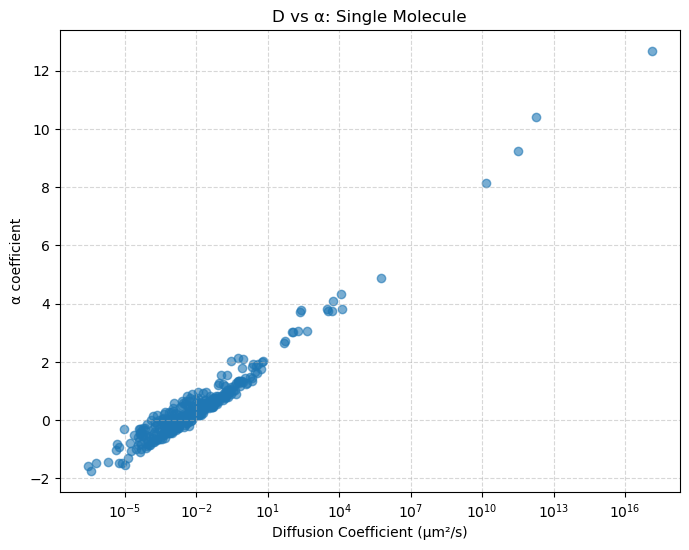

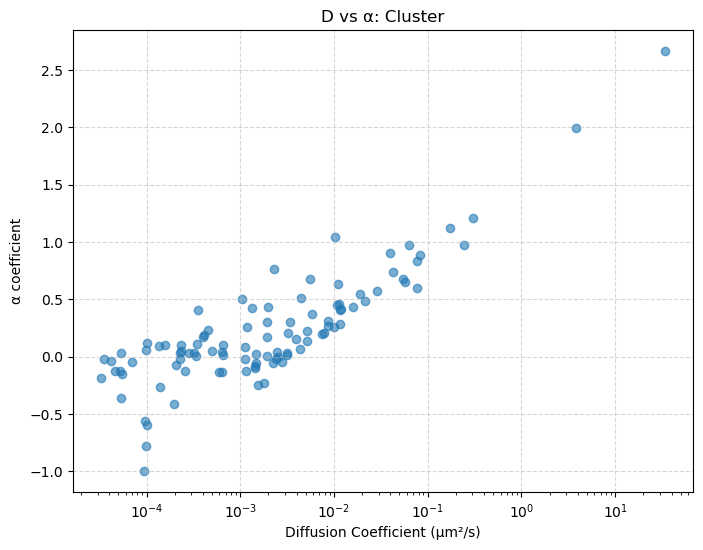

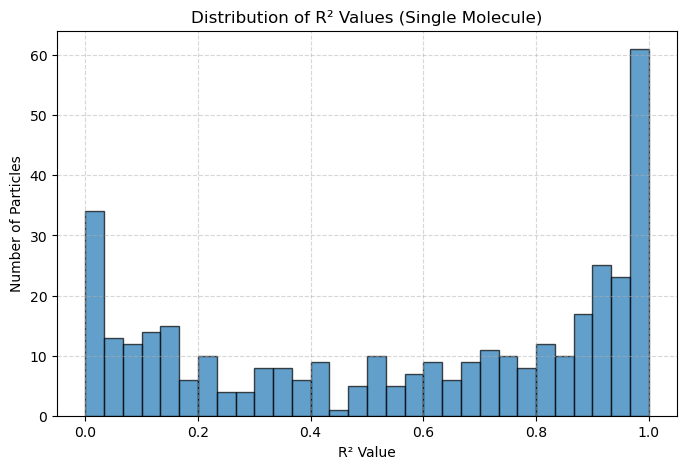

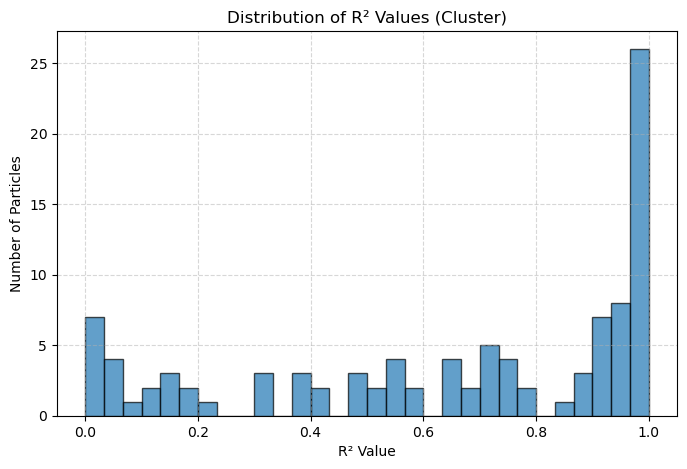

In [78]:
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

# === MSD Model ===
def msd_fit_function(t, D, alpha):
    return 4 * D * t**alpha

# === Optional: Per-Particle MSD Fit Plot ===
def plot_msd_fit(t_valid, r2_valid, D, alpha, r2_score_value, particle_id):
    t_fit = np.linspace(t_valid.min(), t_valid.max(), 100)
    r2_fit = msd_fit_function(t_fit, D, alpha)

    plt.figure(figsize=(6, 4))
    plt.scatter(t_valid, r2_valid, label='Data', color='blue')
    plt.plot(t_fit, r2_fit, label=f'Fit: D={D:.2e}, α={alpha:.2f}, R²={r2_score_value:.2f}', color='red')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Time Lag (t)')
    plt.ylabel('MSD (r²)')
    plt.title(f'MSD Fit for Particle {particle_id}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# === Main MSD Fitting Function ===
def fit_particles(msd_data, original_df, file_path, plot_each=False):
    results = []
    msd_data = msd_data.dropna(axis=1, how='all')  # remove empty columns

    for particle_id in msd_data.columns:
        try:
            t = msd_data.index.values
            r2 = msd_data[particle_id].values

            valid = ~np.isnan(r2) & (r2 > 0)
            t_valid = t[valid][:3]
            r2_valid = r2[valid][:3]

            if len(t_valid) < 3:
                print(f"Skipping particle {particle_id}: fewer than 3 valid MSD points.")
                continue

            popt, _ = curve_fit(msd_fit_function, t_valid, r2_valid, p0=[0.1, 1.0], maxfev=10000)
            D, alpha = popt
            r2_pred = msd_fit_function(t_valid, *popt)
            r_squared = r2_score(r2_valid, r2_pred)

            if plot_each:
                plot_msd_fit(t_valid, r2_valid, D, alpha, r_squared, particle_id)

            results.append({
                'particle': particle_id,
                'Diffusion Coefficient': D,
                'alpha': alpha,
                'R²': r_squared
            })

        except Exception as e:
            print(f"Error fitting particle {particle_id}: {e}")

    results_df = pd.DataFrame(results)

    if not results_df.empty:
        results_df.set_index('particle', inplace=True)
        original_df.set_index('particle', inplace=True)
        for col in results_df.columns:
            original_df[col] = results_df[col]
        original_df.reset_index(inplace=True)

    original_df.to_csv(file_path, index=False)
    print(f"✅ Updated CSV saved to: {file_path}")
    return results_df.reset_index()

# === Histogram of R² ===
def plot_r2_histogram(results_df, label_prefix=''):
    r2_values = results_df['R²'].dropna()
    if r2_values.empty:
        print(f"No R² data available for {label_prefix}")
        return

    plt.figure(figsize=(8, 5))
    plt.hist(r2_values, bins=30, edgecolor='black', alpha=0.7)
    plt.xlabel('R² Value')
    plt.ylabel('Number of Particles')
    plt.title(f'Distribution of R² Values ({label_prefix})')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# === D vs α Scatter Plot ===
def plot_D_vs_alpha(results_df, label_prefix=''):
    data = results_df.dropna(subset=['Diffusion Coefficient', 'alpha'])
    if data.empty:
        print(f"No D vs α data for {label_prefix}")
        return

    plt.figure(figsize=(8, 6))
    plt.scatter(data['Diffusion Coefficient'], data['alpha'], alpha=0.6)
    plt.xscale('log')
    plt.xlabel('Diffusion Coefficient (μm²/s)')
    plt.ylabel('α coefficient')
    plt.title(f'D vs α: {label_prefix}')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
    
# Fit MSD data
single_molecule_results = fit_particles(im_single_molecule, df, file_path, plot_each=False)
cluster_results = fit_particles(im_cluster, df, file_path, plot_each=False)

# Plot outputs
plot_D_vs_alpha(single_molecule_results, label_prefix='Single Molecule')
plot_D_vs_alpha(cluster_results, label_prefix='Cluster')

plot_r2_histogram(single_molecule_results, label_prefix='Single Molecule')
plot_r2_histogram(cluster_results, label_prefix='Cluster')


Final CSV saved after applying R² threshold: 0.7


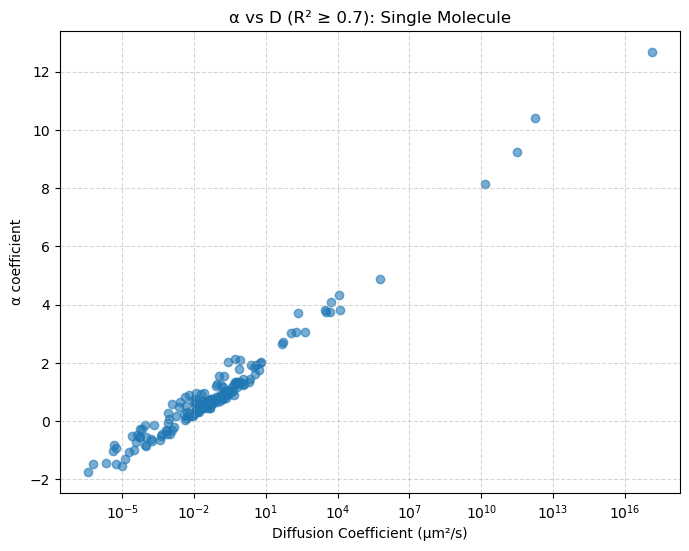

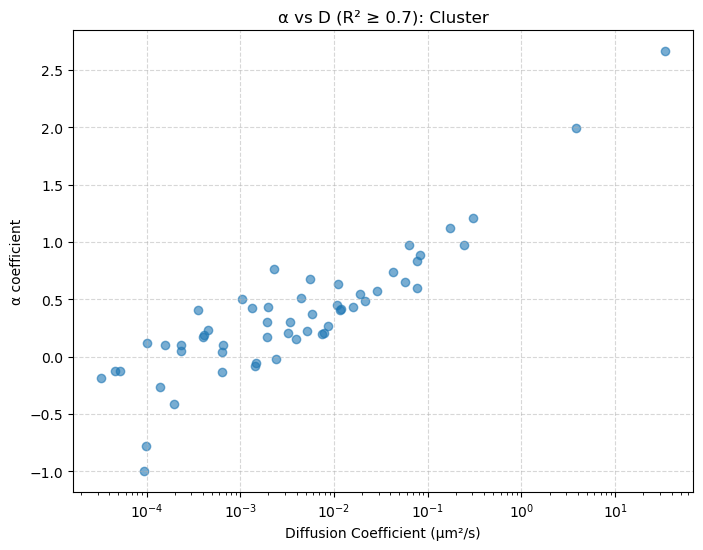

In [79]:
# Define R² threshold
R_squared_threshold = 0.70

# Apply threshold to single molecule results
single_molecule_results.loc[
    single_molecule_results['R²'] < R_squared_threshold,
    ['Diffusion Coefficient', 'alpha']
] = np.nan

# Apply threshold to cluster results
cluster_results.loc[
    cluster_results['R²'] < R_squared_threshold,
    ['Diffusion Coefficient', 'alpha']
] = np.nan

# Update the original DataFrame with cleaned values
for col in ['Diffusion Coefficient', 'alpha', 'R²']:
    df[col] = df['particle'].map(single_molecule_results.set_index('particle')[col]).combine_first(
              df['particle'].map(cluster_results.set_index('particle')[col]))

# Save the final filtered results to CSV
df.to_csv(file_path, index=False)
print(f"Final CSV saved after applying R² threshold: {R_squared_threshold}")

def plot_D_vs_alpha(filtered_df, label, threshold=0.85):
    # Filter for valid alpha, D, and R² above threshold
    data = filtered_df[
        (~filtered_df['alpha'].isna()) &
        (~filtered_df['Diffusion Coefficient'].isna()) &
        (filtered_df['R²'] >= threshold)
    ]

    if data.empty:
        print(f"No valid data above R² threshold for {label}")
        return

    plt.figure(figsize=(8, 6))
    plt.scatter(data['Diffusion Coefficient'], data['alpha'], alpha=0.6)
    plt.xscale('log')
    plt.xlabel('Diffusion Coefficient (μm²/s)')
    plt.ylabel('α coefficient')
    plt.title(f'α vs D (R² ≥ {threshold}): {label}')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
    
plot_D_vs_alpha(single_molecule_results, 'Single Molecule', threshold=R_squared_threshold)
plot_D_vs_alpha(cluster_results, 'Cluster', threshold=R_squared_threshold)


In [80]:
df = pd.read_csv(file_path)

# Classification into single molecule and cluster
single_molecule = df[df['classification'] == 'single molecule'].copy()
cluster = df[df['classification'] == 'cluster'].copy()

# Classify based on alpha
slow_single_molecule = single_molecule[single_molecule['alpha'] <= 0.8]
normal_single_molecule = single_molecule[(single_molecule['alpha'] > 0.8) & (single_molecule['alpha'] <= 1.2)]
fast_single_molecule = single_molecule[single_molecule['alpha'] > 1.2]

slow_cluster = cluster[cluster['alpha'] <= 0.8]
normal_cluster = cluster[(cluster['alpha'] > 0.8) & (cluster['alpha'] <= 1.2)]
fast_cluster = cluster[cluster['alpha'] > 1.2]

# Total counts
total_single_molecule = len(slow_single_molecule) + len(normal_single_molecule) + len(fast_single_molecule)
total_cluster = len(slow_cluster) + len(normal_cluster) + len(fast_cluster)

# Percentages
def calc_pct(part, total): return (len(part) / total * 100) if total > 0 else 0

pct_slow_sm = calc_pct(slow_single_molecule, total_single_molecule)
pct_norm_sm = calc_pct(normal_single_molecule, total_single_molecule)
pct_fast_sm = calc_pct(fast_single_molecule, total_single_molecule)

pct_slow_cl = calc_pct(slow_cluster, total_cluster)
pct_norm_cl = calc_pct(normal_cluster, total_cluster)
pct_fast_cl = calc_pct(fast_cluster, total_cluster)

# Mean diffusion coefficients
mean_D = lambda df: df['Diffusion Coefficient'].mean() if not df.empty else 0

mean_d_slow_sm = mean_D(slow_single_molecule)
mean_d_norm_sm = mean_D(normal_single_molecule)
mean_d_fast_sm = mean_D(fast_single_molecule)

mean_d_slow_cl = mean_D(slow_cluster)
mean_d_norm_cl = mean_D(normal_cluster)
mean_d_fast_cl = mean_D(fast_cluster)

# Print results
print(file_path)
print(f"{'Category':<30} || {'Count':<10} || {'Percentage':<11} || {'Avg D (μm²/s)':<15}")
print(f"{'-'*30} || {'-'*10} || {'-'*11} || {'-'*15}")
print(f"{'Slow Single Molecule':<30} || {len(slow_single_molecule):<10} || {pct_slow_sm:6.2f}%   || {mean_d_slow_sm:12.4f}")
print(f"{'Normal Single Molecule':<30} || {len(normal_single_molecule):<10} || {pct_norm_sm:6.2f}%   || {mean_d_norm_sm:12.4f}")
print(f"{'Fast Single Molecule':<30} || {len(fast_single_molecule):<10} || {pct_fast_sm:6.2f}%   || {mean_d_fast_sm:12.4f}")
print(f"{'Slow Cluster':<30} || {len(slow_cluster):<10} || {pct_slow_cl:6.2f}%   || {mean_d_slow_cl:12.4f}")
print(f"{'Normal Cluster':<30} || {len(normal_cluster):<10} || {pct_norm_cl:6.2f}%   || {mean_d_norm_cl:12.4f}")
print(f"{'Fast Cluster':<30} || {len(fast_cluster):<10} || {pct_fast_cl:6.2f}%   || {mean_d_fast_cl:12.4f}")

# === Plotting trajectories ===

# Ensure you have image dimensions
image_height, image_width = 512, 512  # Replace with actual shape from your image stack if needed
common_xlim = (0, image_width)
common_ylim = (0, image_height)

# Trajectory plotting function
def plot_trajectory(data, title):
    if not data.empty:
        plt.figure(figsize=(6, 5))
        tp.plot_traj(data, label=False, colorby='particle')
        plt.title(title)
        plt.xlim(common_xlim)
        plt.ylim(common_ylim)
        plt.xlabel('x (pixels)')
        plt.ylabel('y (pixels)')
        plt.gca().invert_yaxis()  # Optional: to match image coordinate system
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

# # Plot by subcategories
# plot_trajectory(slow_single_molecule, 'Slow Single Molecule')
# plot_trajectory(normal_single_molecule, 'Normal Single Molecule')
# plot_trajectory(fast_single_molecule, 'Fast Single Molecule')
# plot_trajectory(slow_cluster, 'Slow Cluster')
# plot_trajectory(normal_cluster, 'Normal Cluster')
# plot_trajectory(fast_cluster, 'Fast Cluster')


30C_AfterActivation_07152025.csv
Category                       || Count      || Percentage  || Avg D (μm²/s)  
------------------------------ || ---------- || ----------- || ---------------
Slow Single Molecule           || 1579       ||  73.37%   ||       0.0191
Normal Single Molecule         || 255        ||  11.85%   ||       0.1868
Fast Single Molecule           || 318        ||  14.78%   || 2048487967896011.7500
Slow Cluster                   || 4503       ||  96.78%   ||       0.0026
Normal Cluster                 || 117        ||   2.51%   ||       0.1020
Fast Cluster                   || 33         ||   0.71%   ||       7.6935


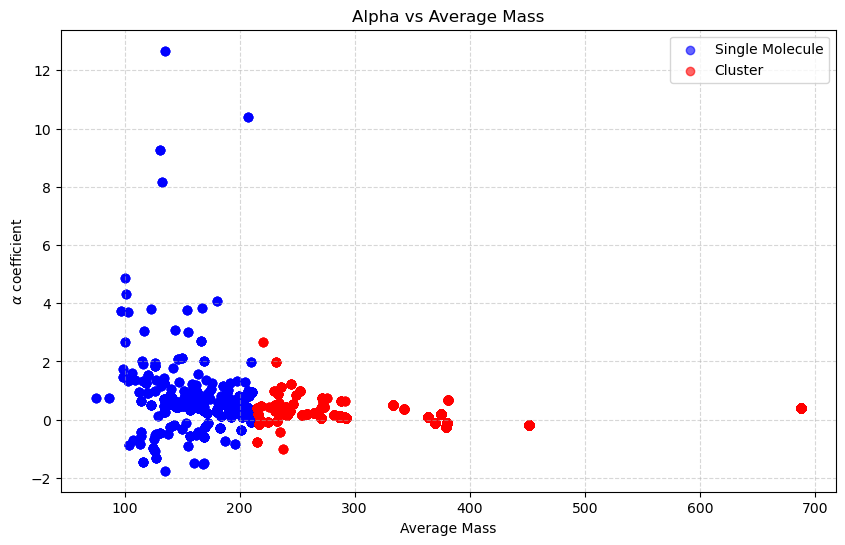

In [81]:
# Extract alpha and average_mass for single molecules
alpha_single = single_molecule['alpha'].values
avg_mass_single = single_molecule['average_mass'].values

# Extract alpha and average_mass for clusters
alpha_cluster = cluster['alpha'].values
avg_mass_cluster = cluster['average_mass'].values

# Create a scatter plot for both single molecules and clusters
plt.figure(figsize=(10, 6))

# Plot for Single Molecule
plt.scatter(avg_mass_single, alpha_single, c='blue', alpha=0.6, label='Single Molecule')

# Plot for Cluster
plt.scatter(avg_mass_cluster, alpha_cluster, c='red', alpha=0.6, label='Cluster')

# Customize the plot
plt.xlabel('Average Mass')
plt.ylabel(r'$\alpha$ coefficient')
plt.title('Alpha vs Average Mass')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Show the plot
plt.show()

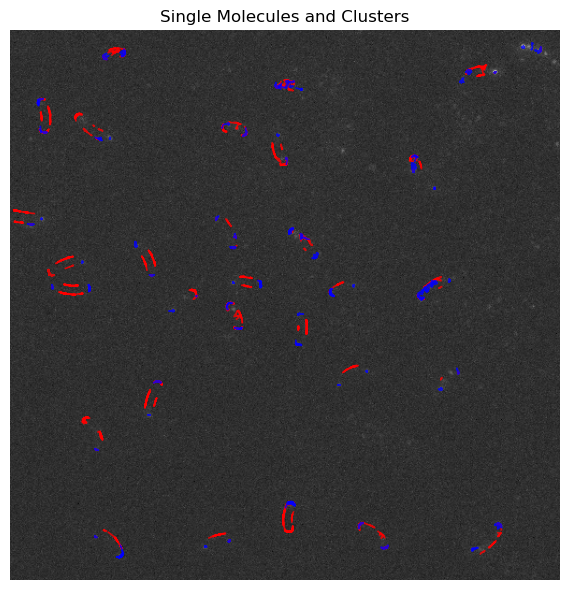

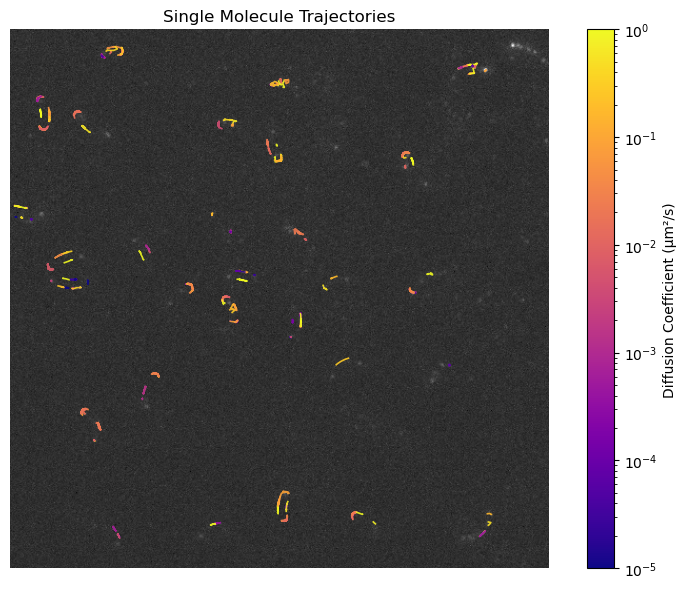

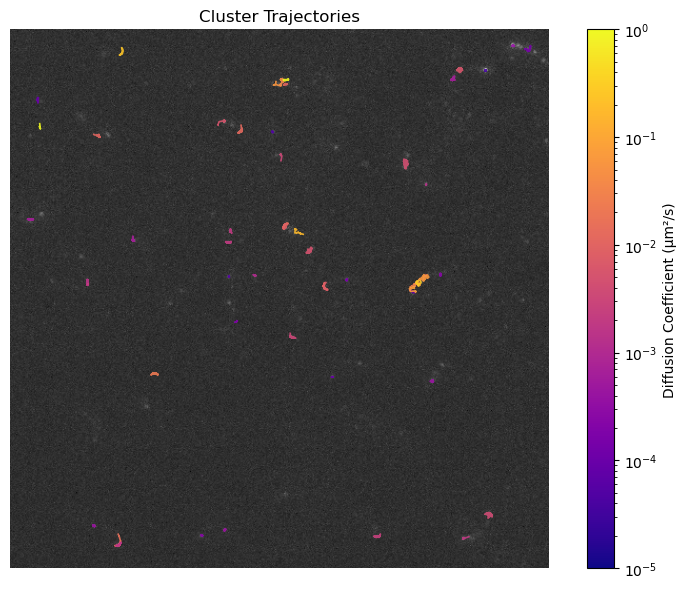

In [82]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import pims

# === Load first image for background ===
background_img = pims.open('30C_AfterActivation/*.jpg')[0]
if background_img.ndim == 3:
    background_img = background_img[:, :, 0]

# === Load the trajectory data ===
metadata_df = pd.read_csv(file_path)

# === Separate single molecules and clusters ===
single_molecule = metadata_df[metadata_df['classification'] == 'single molecule']
cluster = metadata_df[metadata_df['classification'] == 'cluster']

# === Set log-scaled color normalization ===
D_min = 1e-5
D_max = 1
norm = mcolors.LogNorm(vmin=D_min, vmax=D_max)
cmap = cm.plasma

# === Helper to plot trajectories ===
def plot_trajectories(df, title):
    plt.figure(figsize=(8, 6))
    plt.imshow(background_img, cmap='gray')

    for pid, traj in df.groupby('particle'):
        D = traj['Diffusion Coefficient'].iloc[0]

        # Skip invalid D
        if D <= 0 or pd.isna(D):
            continue

        # Clamp D within range
        D = np.clip(D, D_min, D_max)
        color = cmap(norm(D))
        plt.plot(traj['x'], traj['y'], color=color, linewidth=1.2, alpha=0.9)

    plt.title(title)
    plt.axis('off')
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, label='Diffusion Coefficient (μm²/s)')
    cbar.ax.set_yscale('log')
    plt.tight_layout()
    plt.show()
    
# === Plot SM in red and Cluster in blue on same plot ===
def plot_red_blue_overlay(sm_df, cluster_df, title):
    plt.figure(figsize=(8, 6))
    plt.imshow(background_img, cmap='gray')

    # Plot single molecule trajectories in red
    for pid, traj in sm_df.groupby('particle'):
        if {'x', 'y'}.issubset(traj.columns):
            plt.plot(traj['x'], traj['y'], color='red', linewidth=1.2, alpha=0.8)

    # Plot cluster trajectories in blue
    for pid, traj in cluster_df.groupby('particle'):
        if {'x', 'y'}.issubset(traj.columns):
            plt.plot(traj['x'], traj['y'], color='blue', linewidth=1.2, alpha=0.8)

    plt.title(title)
    plt.axis('off')
    red_patch = plt.Line2D([0], [0], color='red', lw=2, label='Single Molecule')
    blue_patch = plt.Line2D([0], [0], color='blue', lw=2, label='Cluster')
#     plt.legend(handles=[red_patch, blue_patch], loc='upper right')
    plt.tight_layout()
    plt.show()

# === Run it
plot_red_blue_overlay(single_molecule, cluster, 'Single Molecules and Clusters')

# === Plot each group
plot_trajectories(single_molecule, 'Single Molecule Trajectories')
plot_trajectories(cluster, 'Cluster Trajectories')

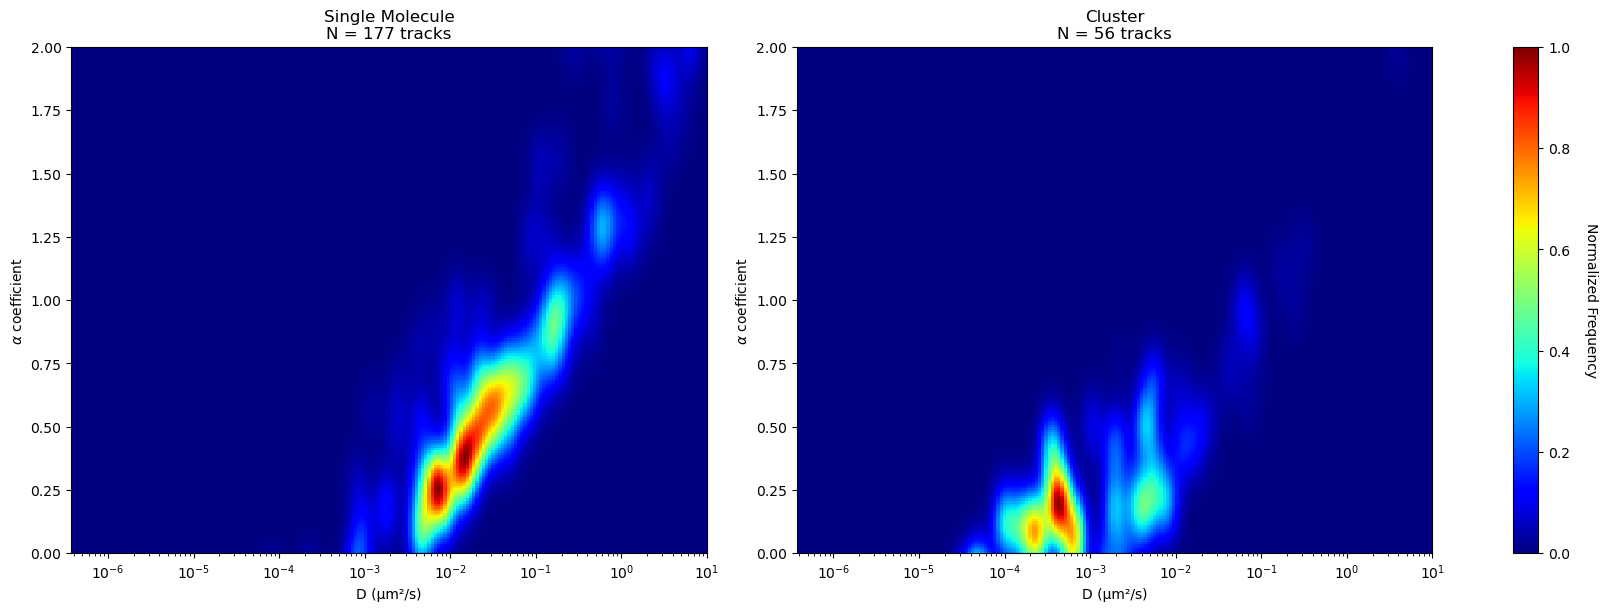

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from sklearn.neighbors import KernelDensity

# === KDE computation ===
def compute_2D_KDE(data_x, data_y, grid_x, grid_y, bandwidth):
    kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth)
    points = np.vstack([data_x, data_y]).T
    kde.fit(points)
    grid_coords = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    log_density = kde.score_samples(grid_coords)
    density = np.exp(log_density).reshape(grid_x.shape)
    density /= density.max()
    return density

# === Heatmap plot ===
def plot_heatmap(D, alpha, title, ax, bandwidth, track_count, D_min, D_max, alpha_min, alpha_max):
    D_grid = np.logspace(np.log10(D_min), np.log10(D_max), 200)
    alpha_grid = np.linspace(alpha_min, alpha_max, 200)
    grid_x, grid_y = np.meshgrid(D_grid, alpha_grid)

    density = compute_2D_KDE(np.log10(D), alpha, np.log10(grid_x), grid_y, bandwidth)

    im = ax.pcolormesh(grid_x, grid_y, density, shading='auto', cmap=plt.cm.jet, norm=Normalize(vmin=0, vmax=1))
    ax.set_xscale('log')
    ax.set_xlim(D_min, D_max)
    ax.set_ylim(alpha_min, alpha_max)
    ax.set_xlabel('D (μm²/s)')
    ax.set_ylabel(r'$\alpha$ coefficient')
    ax.set_title(f"{title}\nN = {track_count} tracks")
    return im

# === Data Filtering ===
# Ensure 'df' is already loaded
single_molecule = df[df['classification'] == 'single molecule'].copy()
cluster = df[df['classification'] == 'cluster'].copy()

# Drop NaNs
single_molecule = single_molecule.dropna(subset=['alpha', 'Diffusion Coefficient'])
cluster = cluster.dropna(subset=['alpha', 'Diffusion Coefficient'])

# Count unique tracks
n_tracks_single = single_molecule['particle'].nunique()
n_tracks_cluster = cluster['particle'].nunique()

# Extract values
alpha_single = single_molecule['alpha'].values
D_single = single_molecule['Diffusion Coefficient'].values

# Plot limits from single molecule data
D_min, D_max = D_single.min(), D_single.max()
alpha_min, alpha_max = alpha_single.min(), alpha_single.max()

# Filter cluster to same plotting range
cluster_filtered = cluster[
    (cluster['Diffusion Coefficient'] >= D_min) &
    (cluster['Diffusion Coefficient'] <= D_max) &
    (cluster['alpha'] >= alpha_min) &
    (cluster['alpha'] <= alpha_max)
].copy()

alpha_cluster = cluster_filtered['alpha'].values
D_cluster = cluster_filtered['Diffusion Coefficient'].values

# === Plot Heatmaps ===
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

im1 = plot_heatmap(D_single, alpha_single, 'Single Molecule', axes[0], bandwidth=0.1,
                   track_count=n_tracks_single, D_min=D_min, D_max=10, alpha_min=0, alpha_max=2)

im2 = plot_heatmap(D_cluster, alpha_cluster, 'Cluster', axes[1], bandwidth=0.1,
                   track_count=n_tracks_cluster, D_min=D_min, D_max=10, alpha_min=0, alpha_max=2)

# Colorbar
cbar = fig.colorbar(im1, ax=axes, orientation='vertical', fraction=0.02, pad=0.05)
cbar.set_label('Normalized Frequency', rotation=270, labelpad=20)

plt.show()

In [84]:
# # Load Data
# df = pd.read_csv(file_path)  # Replace `file_path` with the actual file path
# frames_shape = frames[0].shape  # Assuming `frames` is a list of image frames
# image_height, image_width = frames_shape[:2]

# # Define x and y limits based on image dimensions
# common_xlim = (0, image_width)
# common_ylim = (0, image_height)

# # Split dataset into Single Molecules and Clusters
# single_molecule_df = df[df['classification'] == 'single molecule']
# cluster_df = df[df['classification'] == 'cluster']

# # Set max number of groups per classification
# num_groups = 6  

# # Create widgets for Single Molecule groups
# single_molecule_widgets = []
# for i in range(num_groups):
#     single_molecule_widgets.append({
#         "label": widgets.HTML(value=f"<b>Single Molecule Group {i+1}</b>"),
#         "d_min": widgets.FloatText(value=0.01, description="Min D:"),
#         "d_max": widgets.FloatText(value=1.0, description="Max D:"),
#         "alpha_min": widgets.FloatText(value=0.5, description="Min α:"),
#         "alpha_max": widgets.FloatText(value=2.0, description="Max α:")
#     })

# # Create widgets for Cluster groups
# cluster_widgets = []
# for i in range(num_groups):
#     cluster_widgets.append({
#         "label": widgets.HTML(value=f"<b>Cluster Group {i+1}</b>"),
#         "d_min": widgets.FloatText(value=0.01, description="Min D:"),
#         "d_max": widgets.FloatText(value=1.0, description="Max D:"),
#         "alpha_min": widgets.FloatText(value=0.5, description="Min α:"),
#         "alpha_max": widgets.FloatText(value=2.0, description="Max α:")
#     })

# # Define a function to filter and plot trajectory for both classifications
# def update_plot_and_csv(*args):
#     clear_output(wait=True)  # Clear previous output to avoid redundancy
#     display(widget_ui)  # Redisplay widgets after clearing
    
#     fig, axes = plt.subplots(4, 3, figsize=(30, 40))  # 12 subplots in a 4x3 grid

#     # Process Single Molecule Groups
#     for i, group in enumerate(single_molecule_widgets):
#         d_min, d_max = group["d_min"].value, group["d_max"].value
#         alpha_min, alpha_max = group["alpha_min"].value, group["alpha_max"].value

#         group_df = single_molecule_df[
#             (single_molecule_df['Diffusion Coefficient'] >= d_min) &
#             (single_molecule_df['Diffusion Coefficient'] <= d_max) &
#             (single_molecule_df['alpha'] >= alpha_min) &
#             (single_molecule_df['alpha'] <= alpha_max)
#         ]

#         ax = axes[i // 3, i % 3]  # Assign subplot position
#         if not group_df.empty:
#             ax.set_title(f"Single Molecule Group {i+1}", fontsize=20)
#             ax.set_xlim(common_xlim)
#             ax.set_ylim(common_ylim)
#             tp.plot_traj(group_df, ax=ax, label=False, colorby='particle')
#             ax.set_xlabel("X Position (pixels)")
#             ax.set_ylabel("Y Position (pixels)")

#             # Save filtered data into CSV
#             output_filename = file_path.replace('.csv', f'_SingleMolecule_Group{i+1}.csv')
#             group_df.to_csv(output_filename, index=False)
#             print(f"Saved Single Molecule Group {i+1} data to {output_filename}")
#         else:
#             ax.set_title(f"Single Molecule Group {i+1} (No Data)", fontsize=20)
#             ax.set_xticks([])
#             ax.set_yticks([])

#     # Process Cluster Groups
#     for i, group in enumerate(cluster_widgets):
#         d_min, d_max = group["d_min"].value, group["d_max"].value
#         alpha_min, alpha_max = group["alpha_min"].value, group["alpha_max"].value

#         group_df = cluster_df[
#             (cluster_df['Diffusion Coefficient'] >= d_min) &
#             (cluster_df['Diffusion Coefficient'] <= d_max) &
#             (cluster_df['alpha'] >= alpha_min) &
#             (cluster_df['alpha'] <= alpha_max)
#         ]

#         ax = axes[(i // 3) + 2, i % 3]  # Assign subplot position in lower rows
#         if not group_df.empty:
#             ax.set_title(f"Cluster Group {i+1}", fontsize=20)
#             ax.set_xlim(common_xlim)
#             ax.set_ylim(common_ylim)
#             tp.plot_traj(group_df, ax=ax, label=False, colorby='particle')
#             ax.set_xlabel("X Position (pixels)")
#             ax.set_ylabel("Y Position (pixels)")

#             # Save filtered data into CSV
#             output_filename = file_path.replace('.csv', f'_Cluster_Group{i+1}.csv')
#             group_df.to_csv(output_filename, index=False)
#             print(f"Saved Cluster Group {i+1} data to {output_filename}")
#         else:
#             ax.set_title(f"Cluster Group {i+1} (No Data)", fontsize=20)
#             ax.set_xticks([])
#             ax.set_yticks([])

#     plt.tight_layout()
#     plt.show()

# # Link widgets to update function
# for group in single_molecule_widgets + cluster_widgets:
#     group["d_min"].observe(update_plot_and_csv, names="value")
#     group["d_max"].observe(update_plot_and_csv, names="value")
#     group["alpha_min"].observe(update_plot_and_csv, names="value")
#     group["alpha_max"].observe(update_plot_and_csv, names="value")

# # Arrange widgets in a vertical column layout
# widget_ui = widgets.VBox([
#     widgets.HTML(value="<h2>Single Molecule Groups</h2>"),
#     widgets.HBox([
#         widgets.VBox([
#             group["label"],
#             group["d_min"],
#             group["d_max"],
#             group["alpha_min"],
#             group["alpha_max"]
#         ]) for group in single_molecule_widgets
#     ]),
#     widgets.HTML(value="<h2>Cluster Groups</h2>"),
#     widgets.HBox([
#         widgets.VBox([
#             group["label"],
#             group["d_min"],
#             group["d_max"],
#             group["alpha_min"],
#             group["alpha_max"]
#         ]) for group in cluster_widgets
#     ])
# ])

# # Display widgets
# display(widget_ui)

# # Initial plot and CSV creation
# update_plot_and_csv()


With the overall drifting motion subtracted out, we plot the trajectories again. We observe nice random walks.

In [85]:
# # Load and process both Single Molecule and Cluster groups
# num_groups = 6  # Number of groups for both classifications
# file_paths_SM = [file_path.replace('.csv', f'_SingleMolecule_Group{i+1}.csv') for i in range(num_groups)]
# file_paths_Cluster = [file_path.replace('.csv', f'_Cluster_Group{i+1}.csv') for i in range(num_groups)]

# # Define a function to fit a Gaussian and plot a histogram
# def plot_histogram_with_gaussian(data, xlabel, title):
#     data = data.dropna()
    
#     # Compute histogram
#     hist, bins = np.histogram(data, bins=20, density=True)
#     bin_centers = (bins[:-1] + bins[1:]) / 2

#     # Define Gaussian function
#     def gaussian(x, amp, mu, sigma):
#         return amp * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))

#     try:
#         # Fit Gaussian model
#         popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[1, np.mean(data), np.std(data)])
#         amp_fit, mu_fit, sigma_fit = popt

#         # Plot histogram
#         plt.figure(figsize=(10, 6))
#         sns.histplot(data, bins=20, kde=False, stat="density", alpha=0.6, edgecolor='black', label='Histogram')

#         # Plot Gaussian fit
#         x_vals = np.linspace(data.min(), data.max(), 1000)
#         plt.plot(x_vals, gaussian(x_vals, *popt), color='red', 
#                  label=f'Gaussian Fit\nμ={mu_fit:.2f}, σ={sigma_fit:.2f}')
        
#         # Labels and title
#         plt.xlabel(xlabel)
#         plt.ylabel("Density")
#         plt.title(title)
#         plt.legend()
#         plt.grid(alpha=0.5)
#         plt.show()

#         return mu_fit, sigma_fit  # Return fitted parameters

#     except RuntimeError:
#         print(f"Gaussian fit failed for {title}")
#         return None, None

# # Function to analyze and visualize each dataset
# def analyze_group(file_path, group_name):
#     print(f"\nProcessing {group_name}...\n")
    
#     # Load data
#     df = pd.read_csv(file_path)

#     # Ensure necessary columns exist
#     required_columns = {'particle', 'mass', 'x', 'y'}
#     if not required_columns.issubset(df.columns):
#         print(f"Skipping {group_name} due to missing columns.")
#         return
    
#     # Compute required statistics
#     df['avg_mass'] = df.groupby('particle')['mass'].transform('mean')
#     df['std_mass'] = df.groupby('particle')['mass'].transform('std')

#     # Remove NaN values (important for Gaussian fitting)
#     df = df.dropna(subset=['avg_mass', 'std_mass'])

#     # Plot histograms for mass and standard deviation
#     mu_avg_mass, sigma_avg_mass = plot_histogram_with_gaussian(
#         df['avg_mass'], 'Average Mass', f'Histogram of Average Mass ({group_name})'
#     )
    
#     if mu_avg_mass is not None and sigma_avg_mass is not None:
#         print(f"{group_name} - Gaussian Fit for Average Mass: μ={mu_avg_mass:.2f}, σ={sigma_avg_mass:.2f}")
#     else:
#         print(f"{group_name} - Gaussian Fit for Average Mass Failed.")

#     mu_std_mass, sigma_std_mass = plot_histogram_with_gaussian(
#         df['std_mass'], 'Standard Deviation of Mass', f'Histogram of Std. Dev. of Mass ({group_name})'
#     )
    
#     if mu_std_mass is not None and sigma_std_mass is not None:
#         print(f"{group_name} - Gaussian Fit for Standard Deviation of Mass: μ={mu_std_mass:.2f}, σ={sigma_std_mass:.2f}")
#     else:
#         print(f"{group_name} - Gaussian Fit for Standard Deviation of Mass Failed.")

#     # Define interactive trajectory plotting function
#     def plot_trajectory(x_min, x_max, y_min, y_max):
#         filtered_df = df[
#             (df['x'] >= x_min) & (df['x'] <= x_max) &
#             (df['y'] >= y_min) & (df['y'] <= y_max)
#         ]
        
#         plt.figure(figsize=(10, 8))
#         plt.title(f"Filtered Trajectories ({group_name})")
#         plt.xlim([x_min, x_max])
#         plt.ylim([y_min, y_max])
#         tp.plot_traj(filtered_df, label=False, colorby='particle')

#     # Create interactive widgets for defining trajectory plot range
#     x_min_widget = widgets.FloatText(value=df['x'].min(), description="X Min:")
#     x_max_widget = widgets.FloatText(value=df['x'].max(), description="X Max:")
#     y_min_widget = widgets.FloatText(value=df['y'].min(), description="Y Min:")
#     y_max_widget = widgets.FloatText(value=df['y'].max(), description="Y Max:")

#     # Arrange widgets and display
#     widget_ui = widgets.VBox([
#         widgets.HBox([x_min_widget, x_max_widget]),
#         widgets.HBox([y_min_widget, y_max_widget])
#     ])
    
#     display(widget_ui)

#     # Use `interactive_output` to update the plot dynamically
#     output = widgets.interactive_output(plot_trajectory, {
#         'x_min': x_min_widget,
#         'x_max': x_max_widget,
#         'y_min': y_min_widget,
#         'y_max': y_max_widget
#     })

#     # Display the trajectory plot
#     display(output)

# # Analyze all Single Molecule Groups
# for i, file_path_SM in enumerate(file_paths_SM):
#     analyze_group(file_path_SM, f"Single Molecule Group {i+1}")

# # Analyze all Cluster Groups
# for i, file_path_Cluster in enumerate(file_paths_Cluster):
#     analyze_group(file_path_Cluster, f"Cluster Group {i+1}")

## Step 4: Analyze trajectories

Trackpy includes several functions to help with some common analyses for particle trajectories. (See the "Static Analysis" and "Motion Analysis" sections of the API reference.)

Here, we can show that these data are consistent with colloidal particles undergoing Brownian motion in water.

### Mean Squared Displacement of Individal Probes

Compute the mean squared displacement (MSD) of each particle using the `imsd` function, and plot MSD vs. lag time.

Since we only analyzed 90 frames, the statistics are poor at large lag times. With more frames, we can study larger lag times.

### Ensemble Mean Squared Displacement

Now use the `emsd` function to compute the ensemble mean squared displacement (EMSD) of all particles:

We can easily fit this ensemble mean-squared displacement to a power law, $At^n$, using a convenience function, `fit_powerlaw`, which performs a linear regression in log space.

In water, a viscous material, the expected power-law exponent $n = 1$. The value of $A = 4D$, where $D$ is the particles' diffusivity. $D$ is related to viscosity $\eta$, particle radius $r$, and temperature $T$ through the Stokes-Einstein equation:

$$
D = \displaystyle\frac{k_B T}{6\pi\eta r}
$$

where $k_B$ is the Boltzmann constant. For particles with a 1.5 $\mu\text{m}$ diameter in room-temperature water, $A \approx 1.3$ $\mu\textrm{m}^2 / \textrm{s}$. Our values of $n$ and $A$ above are not far off. (If you'd like to know more about this measurement and its uncertainty, [this paper](https://dx.doi.org/10.1119/1.4803529) is a thorough discussion at the advanced undergraduate level.)

**This is the end of the walkthrough. Keep reading to review a few more advanced capabilities in trackpy.**

# Preview of Some Advanced Features

**Check out the other tutorials for in-depth explorations of these topics and more!**

## Parallelization
Feature-finding can easily be parallelized: each frame is an independent task, and tasks can be divided among the multiple CPUs in a modern computer. Starting with trackpy v0.4.2, this capability is built into `batch`. See the [parallelization tutorial](http://nbviewer.ipython.org/github/soft-matter/trackpy-examples/blob/master/notebooks/parallel-locate.ipynb) for details.

In [69]:
%timeit tp.batch(frames[:20], 11, invert=True, minmass=20, processes='auto')

Frame 19: 3246 features
3.16 s ± 56.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


## Optional High Performance Component: Numba

The core, time-consuming steps in particle location and linking are implemented in Python/numpy and also in pure Python optimized for numba. If numba is installed, trackpy will detect it and use it by default. You can switch it on and off to compare performance.

In [36]:
%timeit tp.batch(frames[:20], 11, invert=True, minmass=20, engine='numba')

Frame 19: 576 features
1.08 s ± 16.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [37]:
%timeit tp.batch(frames[:20], 11, invert=True, minmass=20, engine='python')

Frame 19: 576 features
3.42 s ± 41.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


The linking functions similarly use numba if it's available; you can control this manually using the `link_strategy` option.

## Streaming

The feature-finding and trajectory-linking functions `batch` and `link` keep all of their results in memory. This approach is simple, but it isn't necessary. We can prcoess an unlimited number of frames if we save the results as we go.

Trackpy includes a class to manage storing an retrieving data framewise in the widely-used HDF5 format. The general idea is easily extensible to other formats.

In [38]:
with tp.PandasHDFStore('data.h5') as s:
    tp.batch(frames, 11, invert=True, minmass=200, output=s)

Frame 299: 328 features


In [39]:
with tp.PandasHDFStore('data.h5') as s:
    # As before, we require a minimum "life" of 5 frames and a memory of 3 frames
    for linked in tp.link_df_iter(s, 5, memory=3):
        s.put(linked)

Frame 299: 328 trajectories present.


You can get results by frame with `s.get(frame_number)` or, when you have sufficient memory, retrieve them all. The results are identifical to what you would obtain using the basic functions `batch` and `link`.

In [40]:
with tp.PandasHDFStore('data.h5') as s:
    trajectories = pd.concat(iter(s))